<a href="https://colab.research.google.com/github/emilianomtz0189/credit-risk-scorecard/blob/main/notebooks/02_exploracion_y_limpieza.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Exploración y limpieza de datos

**Objetivo:** entender la calidad de los datos, corregir valores imposibles y ver qué variables se relacionan con el incumplimiento, **usando solo la muestra de entrenamiento**.

El notebook tiene tres partes:
- **A. Calidad de datos:** faltantes, valores imposibles y valores extremos.
- **B. Limpieza:** reglas de negocio que se aprenden con entrenamiento y se aplican igual a prueba.
- **C. Relación con la variable objetivo:** tasa de malos por tramos de cada variable. Es la antesala del WoE de la etapa 3.

> **Regla de oro:** la muestra de prueba no se explora. Solo se le aplican, al final, las mismas reglas aprendidas con entrenamiento.

## Entorno

Conecta Google Drive, clona el repositorio e instala las librerías con las versiones fijadas en `requirements.txt`.

In [1]:
import os
import sys
from pathlib import Path

USUARIO_GITHUB = "emilianomtz0189"
NOMBRE_REPO = "credit-risk-scorecard"
CARPETA_DRIVE = Path("/content/drive/MyDrive/credit-risk-scorecard")  # Donde está cs-training.csv

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    ruta_repo = Path("/content") / NOMBRE_REPO
    if not ruta_repo.exists():
        !git clone -q https://github.com/{USUARIO_GITHUB}/{NOMBRE_REPO}.git {ruta_repo}
    else:
        !git -C {ruta_repo} pull -q
    os.chdir(ruta_repo)
elif Path.cwd().name == "notebooks":
    os.chdir("..")

sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

Mounted at /content/drive
Directorio de trabajo: /content/credit-risk-scorecard


In [2]:
!pip install -q -r requirements.txt

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.datos import copiar_datos_crudos, obtener_particiones, resumen_estructura
from src.eda import (
    graficar_tasa_malos,
    pares_correlacionados,
    resumen_percentiles,
    tasa_malos,
    tasa_malos_por_faltante,
    tasa_malos_por_tramos,
)
from src.limpieza import ATRASOS_MAXIMO_POSIBLE, VARIABLES_ATRASO, LimpiadorCredito

config.fijar_semilla()
config.crear_carpetas()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 30)

In [4]:
# En una sesión nueva de Colab se copian los datos desde Drive y se
# regenera la partición del notebook 01 (idéntica gracias a la semilla).
copiar_datos_crudos(CARPETA_DRIVE)
train, test = obtener_particiones()

Y = config.COLUMNA_OBJETIVO
TASA_GLOBAL = train[Y].mean()
print(f"Entrenamiento: {len(train):,} clientes | Tasa de malos: {TASA_GLOBAL:.2%}")

Copiado cs-training.csv a data/raw/cs-training.csv
Entrenamiento: 105,000 clientes | Tasa de malos: 6.68%


# A. Calidad de datos

## A.1 Estadísticos con percentiles extremos

La media es engañosa cuando hay valores atípicos: un solo cliente con un valor absurdo la mueve mucho. Por eso se revisan los **percentiles 1 % y 99 %** junto al mínimo y el máximo. Si el máximo está muy lejos del percentil 99, hay unos pocos valores extremos.

In [5]:
resumen_percentiles(train.drop(columns=Y))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
uso_credito_revolvente,"105,000.0000",6.4827,267.7813,0.0000,0.0000,0.0000,0.0296,0.1536,0.5601,1.0000,1.0953,"50,708.0000"
edad,"105,000.0000",52.2777,14.7610,21.0000,24.0000,29.0000,41.0000,52.0000,63.0000,78.0000,87.0000,109.0000
atrasos_30_59,"105,000.0000",0.4158,4.1254,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,4.0000,98.0000
razon_deuda,"105,000.0000",355.0537,"2,200.0620",0.0000,0.0000,0.0044,0.1759,0.3676,0.8612,"2,444.0500","4,977.0200","329,664.0000"
ingreso_mensual,"84,277.0000","6,613.0494","11,166.6744",0.0000,0.0000,"1,271.6000","3,400.0000","5,382.0000","8,227.0000","14,583.0000","25,000.0000","1,794,060.0000"
num_creditos_abiertos,"105,000.0000",8.4664,5.1499,0.0000,0.0000,2.0000,5.0000,8.0000,11.0000,18.0000,25.0000,58.0000
atrasos_90,"105,000.0000",0.2608,4.1009,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,3.0000,98.0000
num_creditos_inmobiliarios,"105,000.0000",1.0193,1.1284,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,3.0000,4.0000,54.0000
atrasos_60_89,"105,000.0000",0.2346,4.0866,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,98.0000
num_dependientes,"102,279.0000",0.7579,1.1140,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,3.0000,4.0000,13.0000


## A.2 Registros duplicados

Se cuentan filas con valores idénticos en todas las columnas. Como cada fila tiene un `id_cliente` distinto, un duplicado puede ser un error de carga o dos clientes con el mismo perfil, algo plausible en variables con muchos ceros (sin atrasos, sin dependientes, etc.).

In [6]:
duplicados = train.duplicated().sum()
print(f"Filas duplicadas en entrenamiento: {duplicados:,} ({duplicados / len(train):.2%})")

Filas duplicadas en entrenamiento: 351 (0.33%)


## A.3 Faltantes: ¿son informativos?

Antes de decidir qué hacer con los faltantes conviene preguntarse: **¿los clientes sin dato se comportan distinto?** Si su tasa de malos es diferente a la de los clientes con dato, que falte el dato **es información** y no conviene "rellenarlo" con la mediana, porque se borraría esa señal.

In [7]:
tasa_malos_por_faltante(train, ["ingreso_mensual", "num_dependientes"])

,clientes_sin_dato,tasa_malos_sin_dato,clientes_con_dato,tasa_malos_con_dato
variable,,,,
ingreso_mensual,20723,0.0548,84277,0.0698
num_dependientes,2721,0.0415,102279,0.0675


## A.4 Edades imposibles

Para contratar un crédito se necesita ser mayor de edad. Una edad menor a 18 es un error de captura.

In [8]:
print(f"Clientes con edad < 18: {(train['edad'] < 18).sum()}")
train["edad"].value_counts().sort_index().head(5)

Clientes con edad < 18: 0


,count
edad,
21,139
22,309
23,465
24,596
25,660


## A.5 Códigos especiales en las variables de atrasos

Las tres variables cuentan **cuántas veces** se atrasó el cliente en los últimos 2 años. En 2 años hay a lo más 24 pagos mensuales, así que **un valor mayor a 24 es imposible** como conteo: probablemente es un código del sistema de origen (por ejemplo, "sin información").

Se revisa: qué valores aparecen arriba de 24, si los códigos aparecen juntos en las tres variables y qué tasa de malos tienen esos clientes.

In [9]:
for var in VARIABLES_ATRASO:
    conteo = train.loc[train[var] > ATRASOS_MAXIMO_POSIBLE, var].value_counts().sort_index()
    print(f"{var}: {conteo.to_dict()}")

atrasos_30_59: {96: 1, 98: 181}
atrasos_60_89: {96: 1, 98: 181}
atrasos_90: {96: 1, 98: 181}


In [10]:
# ¿En cuántas de las tres variables aparece el código, por cliente?
num_codigos = (train[VARIABLES_ATRASO] > ATRASOS_MAXIMO_POSIBLE).sum(axis=1)
print("Clientes según número de variables con código:")
print(num_codigos.value_counts().sort_index().to_string())

Clientes según número de variables con código:
0    104818
3       182


In [11]:
# Tasa de malos: clientes con código vs. sin código
tiene_codigo = (num_codigos > 0).map({True: "con código", False: "sin código"})
tasa_malos(train, tiene_codigo)

,clientes,malos,tasa_malos
con código,182,99,0.5440
sin código,104818,6919,0.0660


## A.6 Uso de crédito revolvente

Es saldo entre límite. Lo normal es que esté entre 0 y 1 (0 % a 100 % del límite). Un valor un poco arriba de 1 es posible (sobregiro), pero valores de miles no tienen sentido como proporción.

In [12]:
rangos_uso = pd.cut(train["uso_credito_revolvente"], bins=[-np.inf, 1, 2, 10, np.inf],
                    labels=["0 a 1", "1 a 2", "2 a 10", "más de 10"])
tasa_malos(train, rangos_uso)

,clientes,malos,tasa_malos
uso_credito_revolvente,,,
0 a 1,102678,6157,0.0600
1 a 2,2062,817,0.3962
2 a 10,91,28,0.3077
más de 10,169,16,0.0947


## A.7 Razón de deuda cuando no hay ingreso

La razón de deuda es **pagos de deuda ÷ ingreso**. Si el ingreso falta o es cero, la división no está definida, así que el valor guardado no puede ser una razón. Se compara la distribución de `razon_deuda` según el ingreso.

In [13]:
grupo_ingreso = np.select(
    [train["ingreso_mensual"].isna(), train["ingreso_mensual"] == 0],
    ["ingreso faltante", "ingreso = 0"],
    default="ingreso > 0",
)
train.groupby(grupo_ingreso)["razon_deuda"].describe(percentiles=[0.5, 0.75, 0.99])

,count,mean,std,min,50%,75%,99%,max
ingreso = 0,"1,146.0000","1,493.2836","2,138.7699",0.0000,913.0000,"2,144.7500","9,935.5000","25,801.0000"
ingreso > 0,"83,131.0000",4.8421,92.0142,0.0000,0.2933,0.4742,2.9781,"7,065.5000"
ingreso faltante,"20,723.0000","1,696.9944","4,677.0199",0.0000,"1,170.0000","2,388.5000","8,177.5600","329,664.0000"


## Hallazgos de la parte A

- **Duplicados:** 351 filas (0.33 %). Se conservan: cada una tiene un `id_cliente` distinto y perfiles idénticos son plausibles en variables con muchos ceros.
- **Faltantes informativos:** los clientes sin ingreso tienen una tasa de malos de 5.48 % frente a 6.98 % con dato; sin número de dependientes, 4.15 % frente a 6.75 %. Imputar con la mediana borraría esa diferencia, así que el faltante se conserva como grupo propio.
- **Edad:** en entrenamiento no hay edades menores a 18 (el mínimo es 21). La regla se mantiene porque también se aplica a prueba y a clientes futuros.
- **Códigos 96 y 98 en atrasos:** 182 clientes, y en todos los casos el código aparece en las tres variables a la vez. Su tasa de malos es de 54.40 %, frente a 6.60 % del resto. Son clientes de muy alto riesgo: eliminarlos o confundirlos con "cero atrasos" perdería esa señal.
- **Uso de crédito revolvente:** entre 1 y 2 veces el límite, la tasa de malos es de 39.62 % (sobregiro real, alto riesgo). Por arriba de 10 baja a 9.47 %, cerca del promedio: esos valores no se comportan como sobregiros y se tratan como errores de captura. Si solo se acotaran, esos clientes caerían en el grupo de mayor riesgo sin serlo.
- **Razón de deuda sin ingreso:** con ingreso positivo, la mediana es 0.29; con ingreso cero o faltante, la mediana pasa de 900. Sin ingreso, el valor no es una razón (probablemente es el monto de la deuda), así que se trata como faltante.

# B. Limpieza

## B.1 Reglas

| Regla | Por qué |
|---|---|
| Edad < 18 → faltante | Valor imposible para un acreditado. |
| Atrasos > 24 → faltante | No es un conteo posible en 2 años; es un código especial. |
| Razón de deuda sin ingreso → faltante | Sin ingreso no existe la razón deuda/ingreso. |
| Uso de crédito > 10 → faltante | No se comporta como un sobregiro real (ver A.6): es un error de captura. |
| Uso de crédito, razón de deuda e ingreso acotados en el percentil 99 | Limita el peso de valores extremos (*winsorización*). |

**¿Por qué no se eliminan esos clientes?** Porque en producción también llegarán solicitudes con datos raros y el modelo debe calificarlas. Además, eliminar filas puede sesgar la muestra si esos clientes tienen un riesgo distinto.

**¿Por qué no se imputan los faltantes?** En un scorecard, los faltantes forman **su propio grupo** al calcular el WoE (etapa 3). Así el modelo aprende el riesgo de "no tener el dato" en lugar de esconderlo con un valor inventado. XGBoost y LightGBM también manejan faltantes directamente.

**¿Por qué el tope se calcula solo con entrenamiento?** Por la misma razón que se separó la muestra de prueba: el percentil 99 es un parámetro aprendido de los datos. Si se calculara con todos los datos, la muestra de prueba influiría en el modelo (fuga de información).

In [14]:
limpiador = LimpiadorCredito(percentil_tope=0.99).fit(train)

print("Topes aprendidos con entrenamiento (percentil 99):")
print(limpiador.topes_.to_string(float_format="{:,.4f}".format))

Topes aprendidos con entrenamiento (percentil 99):
uso_credito_revolvente        1.0673
razon_deuda                   2.9781
ingreso_mensual          25,000.0000


In [15]:
# Registros que modifica cada regla en entrenamiento
limpiador.reporte(train)

,registros,pct
edad < 18 -> faltante,0,0.0000
atrasos_30_59 > 24 -> faltante,182,0.1700
atrasos_60_89 > 24 -> faltante,182,0.1700
atrasos_90 > 24 -> faltante,182,0.1700
razon_deuda sin ingreso -> faltante,21869,20.8300
uso_credito_revolvente > 10 -> faltante,169,0.1600
uso_credito_revolvente > 1.07 -> tope,1049,1.0000
razon_deuda > 2.98 -> tope,832,0.7900
"ingreso_mensual > 25,000.00 -> tope",788,0.7500


In [16]:
train_limpio = limpiador.transform(train)
test_limpio = limpiador.transform(test)   # Mismas reglas y mismos topes

resumen_estructura(train_limpio)

,tipo,nulos,pct_nulos,valores_unicos,minimo,maximo
malo,int64,0,0.0000,2,0.0000,1.0000
uso_credito_revolvente,float64,169,0.1600,87343,0.0000,1.0673
edad,float64,0,0.0000,83,21.0000,109.0000
atrasos_30_59,float64,182,0.1700,14,0.0000,13.0000
razon_deuda,float64,21869,20.8300,76609,0.0000,2.9781
ingreso_mensual,float64,20723,19.7400,11642,0.0000,"25,000.0000"
num_creditos_abiertos,int64,0,0.0000,57,0.0000,58.0000
atrasos_90,float64,182,0.1700,17,0.0000,17.0000
num_creditos_inmobiliarios,int64,0,0.0000,27,0.0000,54.0000
atrasos_60_89,float64,182,0.1700,9,0.0000,11.0000


In [17]:
train_limpio.to_csv(config.ARCHIVO_TRAIN_LIMPIO)
test_limpio.to_csv(config.ARCHIVO_TEST_LIMPIO)
print("Guardado:", config.ARCHIVO_TRAIN_LIMPIO.relative_to(config.RAIZ), "y",
      config.ARCHIVO_TEST_LIMPIO.relative_to(config.RAIZ))

Guardado: data/processed/train_limpio.csv y data/processed/test_limpio.csv


# C. Relación con la variable objetivo

Para cada variable se divide a los clientes en tramos y se calcula la **tasa de malos** de cada tramo. La línea punteada es la tasa global.

Qué buscar:
- **Tendencia clara** (la tasa sube o baja de forma ordenada): la variable separa bien a buenos de malos y será buena predictora.
- **Tasa plana**, igual en todos los tramos: la variable aporta poco.
- **Grupo "Faltante"**: si su tasa difiere de la global, el faltante es informativo.

Este análisis es la base intuitiva del **WoE** y el **IV** de la etapa 3, que miden lo mismo de forma numérica.

- Variables continuas: se cortan en **deciles** (10 grupos con el mismo número de clientes).
- Variables de conteo: un grupo por valor (0, 1, 2, ...), con el último como "k o más".

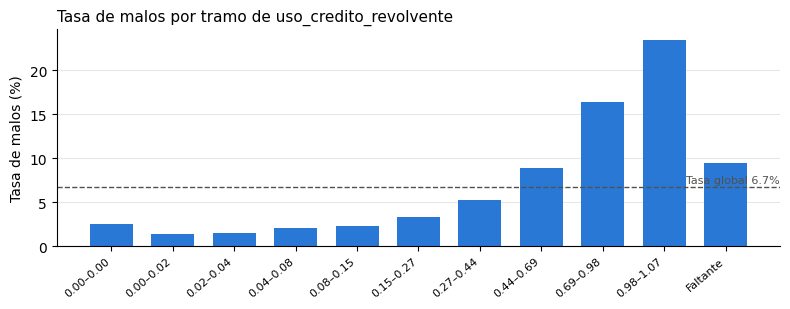

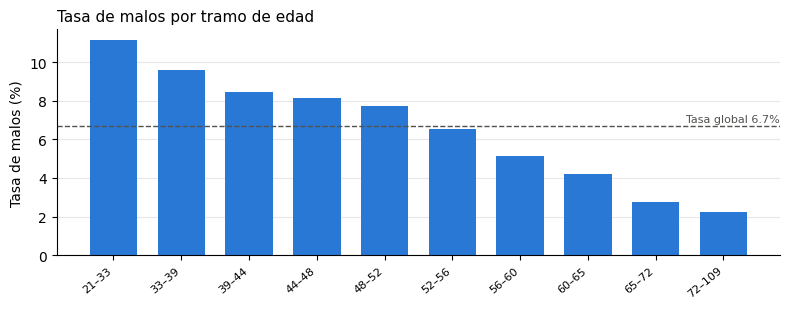

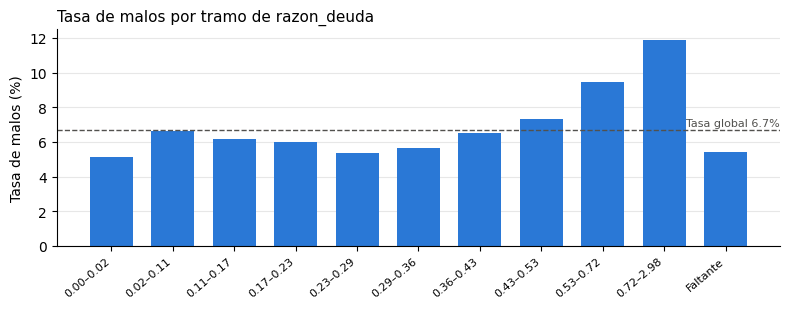

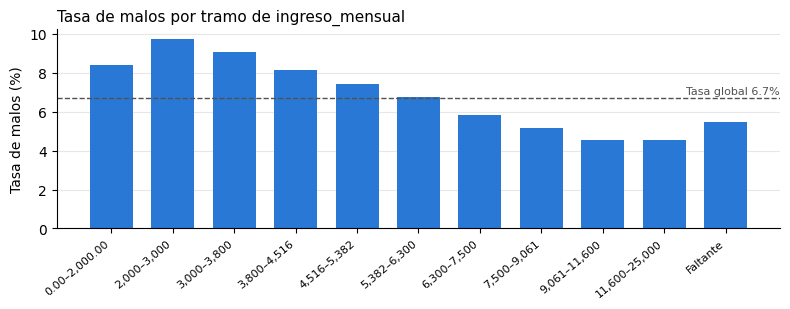

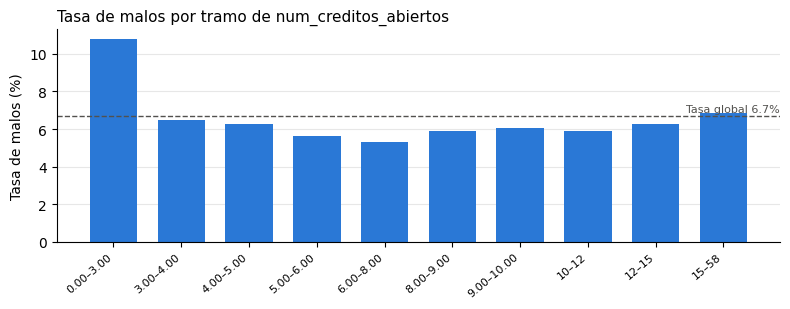

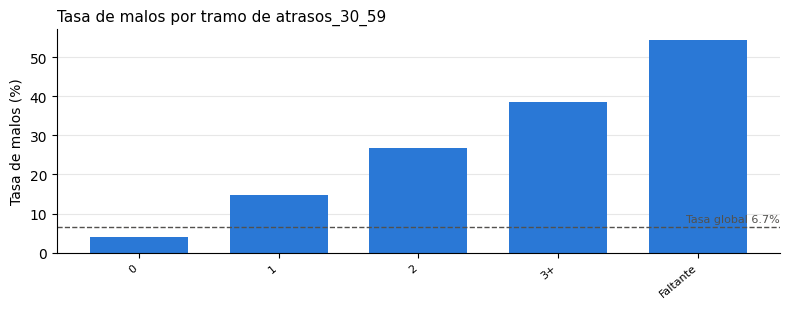

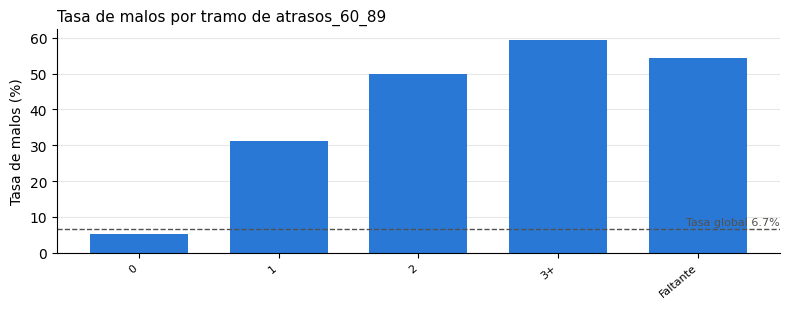

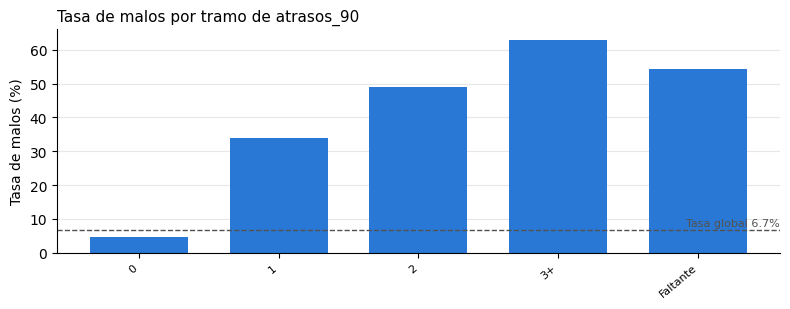

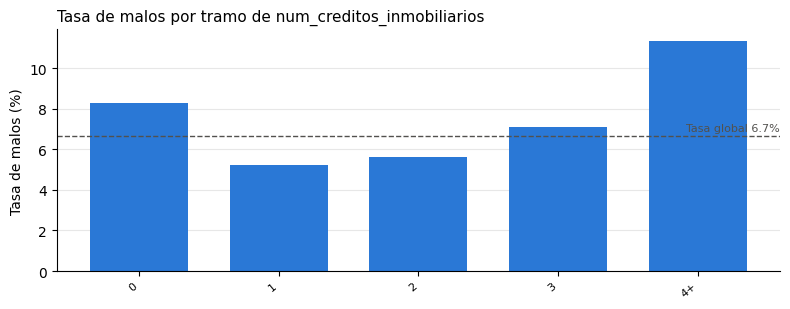

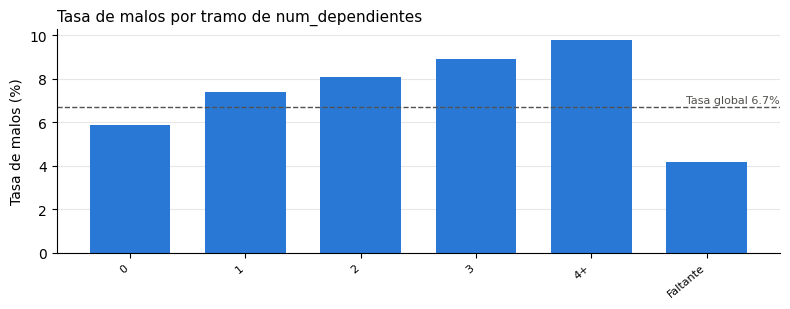

In [18]:
# Variable -> tope para variables de conteo (None = deciles)
tramos_por_variable = {
    "uso_credito_revolvente": None,
    "edad": None,
    "razon_deuda": None,
    "ingreso_mensual": None,
    "num_creditos_abiertos": None,
    "atrasos_30_59": 3,
    "atrasos_60_89": 3,
    "atrasos_90": 3,
    "num_creditos_inmobiliarios": 4,
    "num_dependientes": 4,
}

tablas_tramos = {}
for variable, tope in tramos_por_variable.items():
    tabla = tasa_malos_por_tramos(train_limpio, variable, tope=tope)
    tablas_tramos[variable] = tabla
    graficar_tasa_malos(tabla, f"Tasa de malos por tramo de {variable}", TASA_GLOBAL)
    plt.show()

## C.2 Variables muy correlacionadas entre sí

Si dos variables dicen casi lo mismo (alta correlación), meter ambas a una regresión logística puede volver inestables sus coeficientes (**multicolinealidad**). Aquí solo se identifican los pares; la decisión de cuál conservar se toma en la etapa 3 con el IV.

In [19]:
pares_correlacionados(train_limpio.drop(columns=Y), umbral=0.5)

,variable_1,variable_2,spearman
0,razon_deuda,num_creditos_inmobiliarios,0.6063


## Resumen de la etapa

- Se revisó la calidad de datos **solo con la muestra de entrenamiento**.
- Reglas aplicadas: edad < 18, atrasos > 24, razón de deuda sin ingreso y uso de crédito > 10 pasan a faltante; uso de crédito, razón de deuda e ingreso se acotan en el percentil 99 de entrenamiento.
- Los faltantes se conservan como grupo propio para la etapa 3.
- Se guardaron `train_limpio.csv` y `test_limpio.csv` en `data/processed/`.

**Siguiente paso:** notebook `03_woe_iv.ipynb`, agrupación de variables y cálculo de WoE e IV.

## Hallazgos de la parte C

- **Atrasos (30–59, 60–89 y 90+ días):** son las variables con la relación más fuerte. La tasa de malos sube de forma ordenada con cada atraso adicional, y el grupo "Faltante" (códigos 96 y 98) está entre los más riesgosos.
- **Uso de crédito revolvente:** la tasa casi no cambia en los usos bajos y crece con fuerza a partir de un uso cercano a la mitad del límite; el tramo más alto (cerca o arriba del 100 %) es el más riesgoso. El grupo "Faltante" (uso mayor a 10) queda cerca del promedio, lo que confirma que esos valores eran errores de captura.
- **Edad:** la tasa de malos baja de forma constante: el decil más joven es el más riesgoso y el de mayor edad, el menos riesgoso.
- **Ingreso mensual:** a mayor ingreso, menor tasa de malos. El primer decil es un poco menos riesgoso que el segundo, y los clientes sin ingreso reportado están por debajo del promedio.
- **Razón de deuda:** relación más débil. La tasa es casi plana en los tramos bajos y solo sube en los más altos.
- **Créditos abiertos:** solo se separa el grupo con menos créditos (más riesgoso); el resto es casi plano.
- **Créditos inmobiliarios:** relación en forma de U: tener 0 o 4 o más es más riesgoso que tener 1 o 2.
- **Dependientes:** la tasa sube con cada dependiente; el grupo sin dato es el menos riesgoso.
- **Correlación:** el único par con Spearman ≥ 0.5 es razón de deuda y créditos inmobiliarios (0.61). Tiene lógica de negocio: una hipoteca suma pagos de deuda. Se revisa en la etapa 3.

**Implicación para el modelo:** varias relaciones no son lineales (forma de U, saltos solo en un extremo). Una regresión logística con las variables crudas no las capturaría bien. Por eso en la etapa 3 las variables se agrupan en tramos y se transforman con **WoE**, que asigna a cada tramo un valor según su riesgo real.